In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv(r"C:\Users\HP\Desktop\apex task 2\Apex planet.csv")


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   str    
 1   Order_Date     1000 non-null   str    
 2   Customer_ID    1000 non-null   str    
 3   Customer_Name  1000 non-null   str    
 4   Age            1000 non-null   int64  
 5   Gender         1000 non-null   str    
 6   City           1000 non-null   str    
 7   Product        1000 non-null   str    
 8   Category       1000 non-null   str    
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(2), int64(2), str(8)
memory usage: 156.5 KB


In [5]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       1000 non-null   str           
 1   Order_Date     1000 non-null   datetime64[us]
 2   Customer_ID    1000 non-null   str           
 3   Customer_Name  1000 non-null   str           
 4   Age            1000 non-null   int64         
 5   Gender         1000 non-null   str           
 6   City           1000 non-null   str           
 7   Product        1000 non-null   str           
 8   Category       1000 non-null   str           
 9   Quantity       1000 non-null   int64         
 10  Unit_Price     1000 non-null   float64       
 11  Total_Sales    1000 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(7)
memory usage: 146.7 KB


In [6]:
sum=df["Total_Sales"].sum()
print("Total sales",sum)

Total sales 139399439.65


In [7]:
statistical_info=df.describe() # std is compare the difference b/w average to minand max
print(statistical_info)

                       Order_Date          Age     Quantity    Unit_Price  \
count                        1000  1000.000000  1000.000000   1000.000000   
mean   2025-07-03 11:19:40.800000    41.353000     5.435000  25486.783410   
min           2025-01-01 00:00:00    18.000000     1.000000    145.780000   
25%           2025-03-30 18:00:00    30.000000     3.000000  13895.722500   
50%           2025-07-01 00:00:00    41.000000     5.000000  25398.740000   
75%           2025-10-07 06:00:00    53.000000     8.000000  37512.382500   
max           2026-01-01 00:00:00    65.000000    10.000000  49997.530000   
std                           NaN    13.683626     2.838632  14179.402361   

         Total_Sales  
count    1000.000000  
mean   139399.439650  
min       437.340000  
25%     47066.632500  
50%    108594.025000  
75%    203722.882500  
max    493677.500000  
std    114100.051546  


In [8]:
gender_count=df["Gender"].value_counts()
print(gender_count)

Gender
Male      511
Female    489
Name: count, dtype: int64


In [9]:
product=df["Product"].value_counts()
print(product)

Product
Mobile    184
Book      178
Laptop    170
Chair     159
Shoes     156
Rice      153
Name: count, dtype: int64


In [10]:
category=df["Category"].value_counts()
print(category)

Category
Electronics    354
Education      178
Furniture      159
Fashion        156
Grocery        153
Name: count, dtype: int64


In [11]:
product_category=df.groupby("Category")["Product"].agg(["nunique","unique"])
print(product_category)

             nunique            unique
Category                              
Education          1            [Book]
Electronics        2  [Mobile, Laptop]
Fashion            1           [Shoes]
Furniture          1           [Chair]
Grocery            1            [Rice]


In [12]:
plt.show()

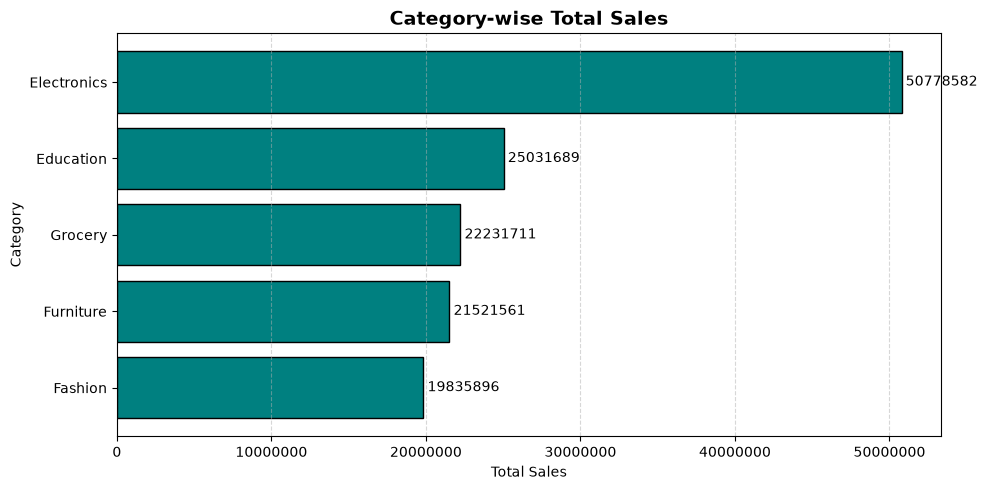

In [22]:


data = df.groupby("Category")["Total_Sales"].sum().sort_values()

plt.figure(figsize=(10, 5))
bars = plt.barh(data.index, data.values, color="teal", edgecolor="black")
plt.bar_label(bars, fmt="%.0f", padding=3)

plt.title("Category-wise Total Sales", fontsize=14, fontweight="bold")
plt.xlabel("Total Sales")
plt.ylabel("Category")
plt.ticklabel_format(axis="x", style="plain")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

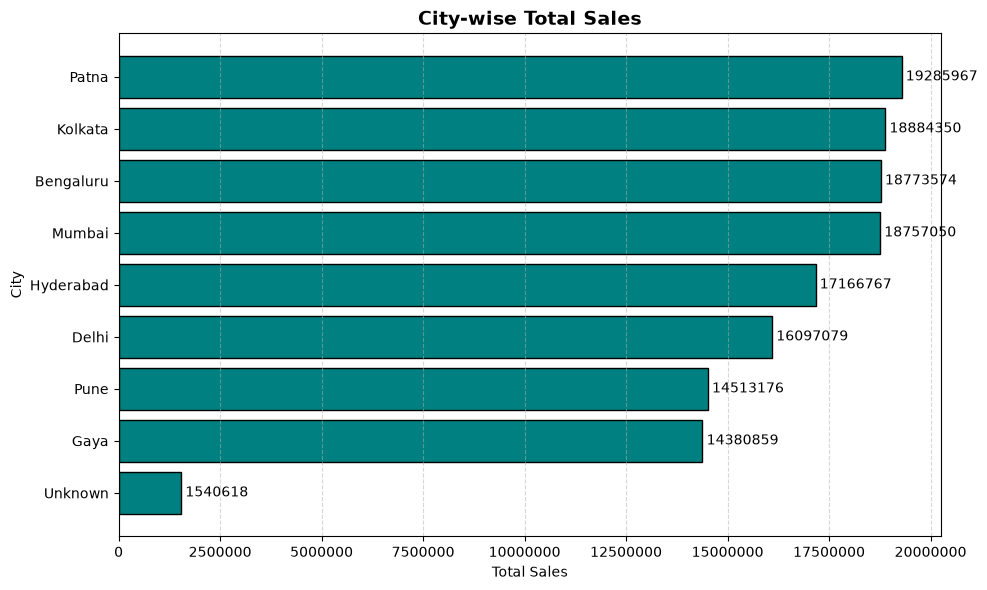

In [21]:
data = df.groupby("City")["Total_Sales"].sum().sort_values()

plt.figure(figsize=(10, 6))
bars = plt.barh(data.index, data.values, color="teal", edgecolor="black")
plt.bar_label(bars, fmt="%.0f", padding=3)

plt.title("City-wise Total Sales", fontsize=14, fontweight="bold")
plt.xlabel("Total Sales")
plt.ylabel("City")
plt.ticklabel_format(axis="x", style="plain")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

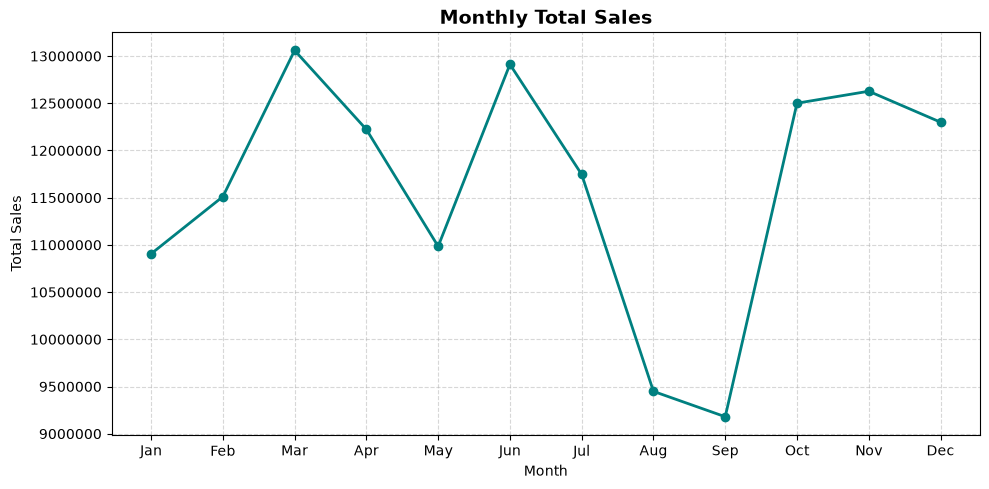

In [20]:

data = df.groupby(df["Order_Date"].dt.month)["Total_Sales"].sum()

plt.figure(figsize=(10, 5))
plt.plot(data.index, data.values, marker="o", color="teal", linewidth=2)

plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun",
                          "Jul","Aug","Sep","Oct","Nov","Dec"])

plt.title("Monthly Total Sales", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.ticklabel_format(axis="y", style="plain")   # 1e7 hatane ke liye
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

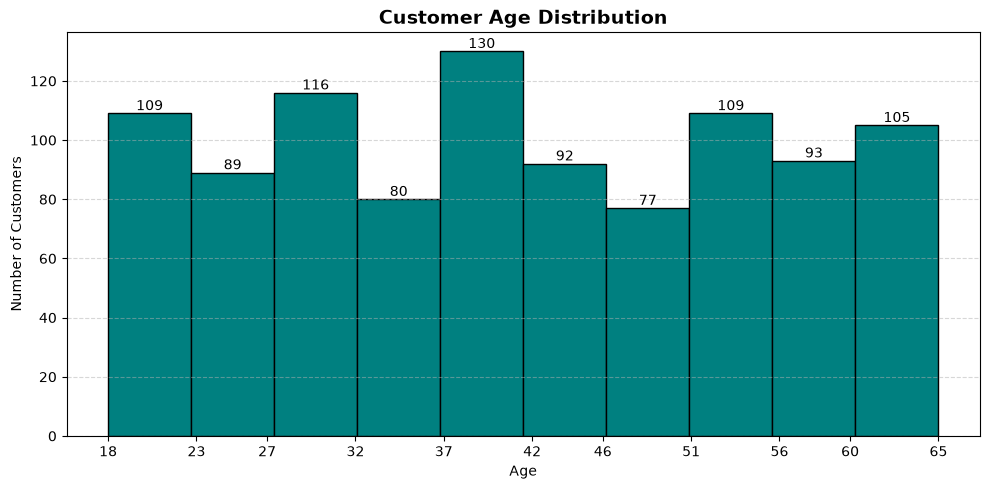

In [23]:

plt.figure(figsize=(10, 5))
counts, bins, patches = plt.hist(df["Age"], bins=10, color="teal", edgecolor="black")
plt.bar_label(patches, fmt="%.0f")

plt.title("Customer Age Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.xticks(bins.round(0))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

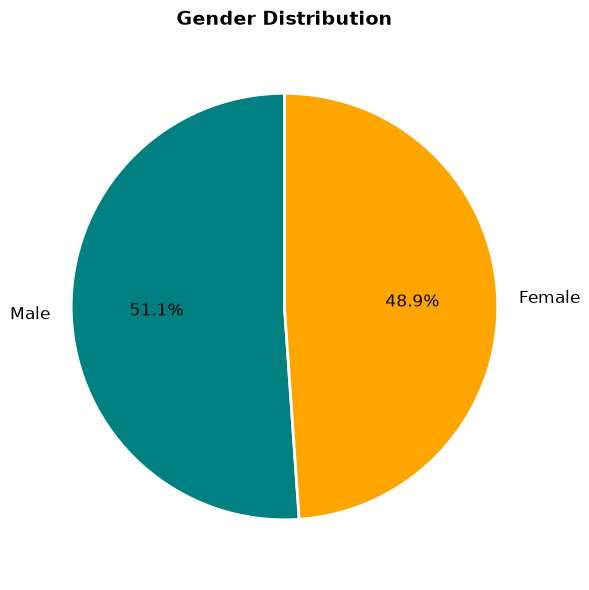

In [24]:


data = df["Gender"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(data.values, labels=data.index, autopct="%1.1f%%",
        colors=["teal", "orange"], startangle=90,
        wedgeprops={"edgecolor": "white", "linewidth": 2},
        textprops={"fontsize": 12})

plt.title("Gender Distribution", fontsize=14, fontweight="bold")
plt.axis("equal")   # chart gol rakhta hai
plt.tight_layout()
plt.show()

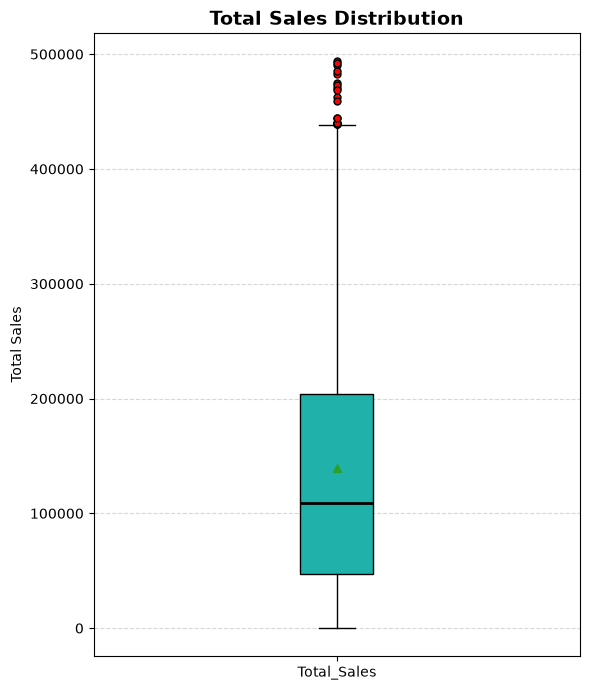

In [25]:
plt.figure(figsize=(6, 7))
plt.boxplot(df["Total_Sales"], patch_artist=True, showmeans=True,
            boxprops=dict(facecolor="lightseagreen"),
            medianprops=dict(color="black", linewidth=2),
            flierprops=dict(marker="o", markerfacecolor="red", markersize=5))

plt.title("Total Sales Distribution", fontsize=14, fontweight="bold")
plt.ylabel("Total Sales")
plt.xticks([1], ["Total_Sales"])
plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

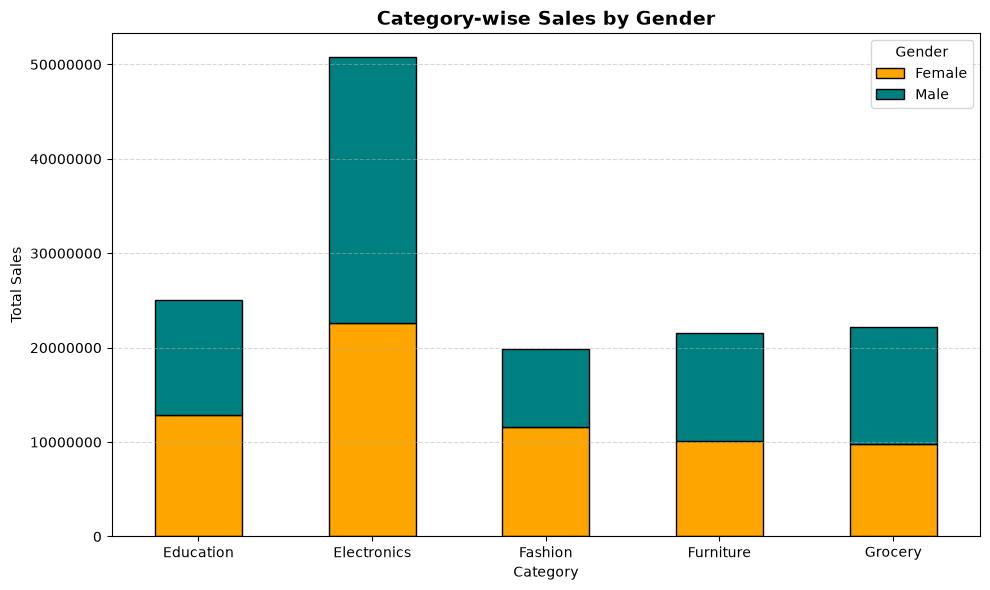

In [26]:

data = df.groupby(["Category", "Gender"])["Total_Sales"].sum().unstack()

ax = data.plot(kind="bar", stacked=True, figsize=(10, 6),
               color=["orange", "teal"], edgecolor="black")

plt.title("Category-wise Sales by Gender", fontsize=14, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.ticklabel_format(axis="y", style="plain")
plt.legend(title="Gender")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

